# 03. Líneas base, candidatos y comparación — OralSolutions

**Objetivo.** Comparar las tres líneas base y **cinco familias tabulares**. Los datos proceden de `src.pipeline`.

- **Predicción:** `abandono_60d = 1` cuando no consta continuidad del mismo tratamiento durante los 60 días posteriores a la sesión atendida.
- **Snapshot etiquetado:** 2.377 observaciones, 321 abandonos (13,50 %). División vigente: **1.195 train / 356 gap / 826 hold-out**; fecha de corte `2025-08-01`.
- **Métrica de selección:** `average_precision` (**AP**, resumen de curva precision-recall); para clases minoritarias, el valor de referencia de un ranking constante es la prevalencia de la clase positiva.
- **Validación:** pliegues temporales expansivos, excluyendo del entrenamiento de cada pliegue etiquetas cuyo horizonte de 60 días no haya madurado al iniciar su validación.
- **Regla contra fuga:** el conjunto **test** queda sellado hasta `05_seleccion.ipynb`. Los gráficos de aquí utilizan exclusivamente **train y CV**.

In [1]:
import sys
import subprocess
import time
import warnings
from pathlib import Path

# Ubicar la raíz del proyecto
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn

from mlflow.models import infer_signature
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    PrecisionRecallDisplay,
)

from src.pipeline import (
    cargar_datos, construir_features, obtener_datos_divididos,
    construir_pipeline, obtener_hash_datos, FECHA_CORTE,
    SEMILLA, FECHA_EVENTO, FEATURES_FINALES,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

# Configuración del experimento
HORIZONTE_DIAS = 60
UMBRAL_REFERENCIA = 0.60
MLFLOW_URI = "http://localhost:5000"
EXPERIMENTO = "OralSolutions"

# Datos y división única
HASH_DATOS = obtener_hash_datos()
X_train, X_test, y_train, y_test = obtener_datos_divididos()

base = construir_features(cargar_datos())
limite_train = pd.Timestamp(FECHA_CORTE) - pd.Timedelta(days=HORIZONTE_DIAS)
dates_train = base.loc[
    base[FECHA_EVENTO] <= limite_train, FECHA_EVENTO
].reset_index(drop=True)

# MLflow y trazabilidad
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENTO)

git_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=ROOT,
    capture_output=True,
    text=True,
).stdout.strip() or "sin_commit"

print(f"Train: {len(X_train):,} | Test reservado: {len(X_test):,}")
print(f"MLflow: {MLFLOW_URI}")


=== DIVISIÓN TEMPORAL ===
Fecha de corte       : 2025-08-01
Horizonte            : 60 días
Límite entrenamiento : 2025-06-02
Train                : 1,195
Hold-out             : 826
Gap excluido         : 356


2026/11/23 18:35:09 INFO mlflow.tracking.fluent: Experiment with name 'OralSolutions' does not exist. Creating a new experiment.


Train: 1,195 | Test reservado: 826
MLflow: http://localhost:5000


## 1. Pliegues temporales con maduración de 60 días

Se generan cinco ventanas sucesivas por **fechas únicas**, evitando separar observaciones del mismo día entre entrenamiento y validación. Antes de cada ventana se purgan las observaciones cuyas etiquetas todavía no habrían madurado al comenzar la validación. Los índices resultantes se reutilizan **idénticos para todos los modelos**.

In [2]:
fechas_unicas = pd.Index(dates_train.drop_duplicates().sort_values())
cv_temporal = []
resumen_pliegues = []
for k, (idx_fecha_train, idx_fecha_val) in enumerate(TimeSeriesSplit(n_splits=5).split(fechas_unicas), 1):
    primera_fecha_val = fechas_unicas[idx_fecha_val[0]]
    ultima_fecha_val = fechas_unicas[idx_fecha_val[-1]]
    limite_etiquetas = primera_fecha_val - pd.Timedelta(days=HORIZONTE_DIAS)
    idx_train = np.flatnonzero((dates_train <= limite_etiquetas).to_numpy())
    idx_val = np.flatnonzero(((dates_train >= primera_fecha_val) & (dates_train <= ultima_fecha_val)).to_numpy())
    if len(idx_train) == 0 or len(idx_val) == 0:
        raise ValueError(f'Pliegue {k} vacío con purga temporal de 60 días.')
    if y_train.iloc[idx_train].nunique() < 2 or y_train.iloc[idx_val].nunique() < 2:
        raise ValueError(f'Pliegue {k} sin las dos clases; revisar ventanas y estrategia de CV.')
    assert dates_train.iloc[idx_train].max() + pd.Timedelta(days=HORIZONTE_DIAS) <= dates_train.iloc[idx_val].min()
    cv_temporal.append((idx_train, idx_val))
    resumen_pliegues.append(dict(pliegue=k, train=len(idx_train), val=len(idx_val),
                                    fin_train=str(dates_train.iloc[idx_train].max().date()),
                                    inicio_val=str(primera_fecha_val.date()),
                                    fin_val=str(ultima_fecha_val.date()),
                                    positivos_val=int(y_train.iloc[idx_val].sum())))

display(pd.DataFrame(resumen_pliegues))

,pliegue,train,val,fin_train,inicio_val,fin_val,positivos_val
0,1,34,134,2024-03-22,2024-05-21,2024-08-15,13
1,2,136,172,2024-06-17,2024-08-16,2024-10-28,12
2,3,259,204,2024-08-30,2024-10-29,2025-01-10,40
3,4,435,255,2024-11-12,2025-01-11,2025-03-22,43
4,5,651,334,2025-01-23,2025-03-24,2025-06-02,42


## 2. Líneas base

Se evalúan tres referencias para interpretar el valor añadido de los modelos:

1. **Dummy mayoritaria:** predice siempre la clase mayoritaria, que ahora es **continuidad (0)**. Sin discriminación útil, su AP es la prevalencia de abandono.
2. **Regla reactiva aproximada:** alerta cuando el ritmo medio de días por sesión supera 14 o existe fricción histórica. **Es una aproximación operativa**: no reproduce literalmente la regla de PSet 1 basada en los 14 días después de la próxima cita, porque ese dato futuro no existe al cierre de la sesión.
3. **Regla «falta una sesión»:** referencia derivada del EDA; el nuevo EDA muestra que **no** es una regla predictiva especialmente fuerte. No se fijan probabilidades ficticias como si fueran calibradas: sus puntuaciones representan una alerta binaria.

In [3]:
class ReglaNegocio14Dias(BaseEstimator, ClassifierMixin):
    """Proxy histórico de contacto reactivo; NO usa información futura de próxima cita."""
    def __init__(self, dias=14.0, min_friccion=1):
        self.dias = dias
        self.min_friccion = min_friccion
    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        alerta = ((X['ritmo_dias_por_sesion'] > self.dias) |
                    (X['friccion_previa'] >= self.min_friccion)).astype(float).to_numpy()
        return np.column_stack([1 - alerta, alerta])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

class Regla1Sesion(BaseEstimator, ClassifierMixin):
    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        alerta = ((X['sesiones_planificadas'] - X['numero_sesion']) == 1).astype(float).to_numpy()
        return np.column_stack([1 - alerta, alerta])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def puntuar_cv(estimador, nombre, familia, fase, umbral=UMBRAL_REFERENCIA):
    """Misma CV para todas las familias; el test queda reservado para 05."""
    t0 = time.perf_counter()
    scores_cv, roc_cv, segundos_cv = [], [], []
    for ind_train, ind_val in cv_temporal:
        fold = clone(estimador)
        t_fold = time.perf_counter()
        fold.fit(X_train.iloc[ind_train], y_train.iloc[ind_train])
        segundos_cv.append(time.perf_counter() - t_fold)
        prob_val = fold.predict_proba(X_train.iloc[ind_val])[:, 1]
        scores_cv.append(average_precision_score(y_train.iloc[ind_val], prob_val))
        roc_cv.append(roc_auc_score(y_train.iloc[ind_val], prob_val))

    ajustado = clone(estimador)
    t_fit = time.perf_counter()
    ajustado.fit(X_train, y_train)
    segundos_fit = time.perf_counter() - t_fit
    prob_train = ajustado.predict_proba(X_train)[:, 1]
    pred_train = (prob_train >= umbral).astype(int)
    pr_train = average_precision_score(y_train, prob_train)
    resultado = {
        'modelo': nombre, 'familia': familia, 'fase': fase,
        'pr_auc_train': float(pr_train),
        'pr_auc_cv_mean': float(np.mean(scores_cv)),
        'pr_auc_cv_std': float(np.std(scores_cv, ddof=1)),
        'brecha_train_cv': float(pr_train - np.mean(scores_cv)),
        'roc_auc_cv_mean': float(np.mean(roc_cv)),
        'f1_train_060': float(f1_score(y_train, pred_train, zero_division=0)),
        'recall_train_060': float(recall_score(y_train, pred_train, zero_division=0)),
        'precision_train_060': float(precision_score(y_train, pred_train, zero_division=0)),
        'segundos_entrenamiento': float(segundos_fit),
        'segundos_cv_total': float(sum(segundos_cv)),
        'segundos_total': float(time.perf_counter() - t0),
        'ap_pliegues': scores_cv,
    }
    return resultado, ajustado


def registrar_mlflow(resultado, modelo_ajustado, registra_modelo=True):
    with mlflow.start_run(run_name=resultado['modelo']) as run:
        mlflow.set_tags({'fase': resultado['fase'], 'familia': resultado['familia'],
                            'git_commit': git_commit, 'snapshot_sha256': HASH_DATOS,
                            'dataset_tabla': 'ORALSOLUTIONS_DW.OBT.OBT_RIESGO_ABANDONO',
                            'fecha_corte': FECHA_CORTE, 'horizonte_dias': str(HORIZONTE_DIAS),
                            'cv': 'temporal_purgada_60d_5_pliegues'})
        mlflow.log_params({'semilla': SEMILLA, 'umbral_referencia': UMBRAL_REFERENCIA,
                            'n_train': len(X_train), 'n_test_reservado': len(X_test),
                            'sha256': HASH_DATOS})
        # Guardar parámetros del estimador; se omiten objetos complejos no serializables.
        for clave, valor in modelo_ajustado.get_params(deep=True).items():
            if valor is None or isinstance(valor, (str, int, float, bool)):
                mlflow.log_param('param_' + clave, str(valor))
        for clave, valor in resultado.items():
            if isinstance(valor, (int, float)) and not isinstance(valor, bool):
                mlflow.log_metric(clave, float(valor))
        for i, val in enumerate(resultado['ap_pliegues'], 1):
            mlflow.log_metric(f'pr_auc_fold_{i}', float(val))
        if registra_modelo:
            # El artefacto contiene el pipeline completo; en las reglas heurísticas,
            # las clases definidas en notebook pueden no ser importables desde una API.
            ejemplo = X_train.head(3)
            firma = infer_signature(ejemplo, modelo_ajustado.predict_proba(ejemplo))
            mlflow.sklearn.log_model(modelo_ajustado, artifact_path='modelo',
                                    signature=firma, input_example=ejemplo)
        return run.info.run_id

## 3. Modelos candidatos por defecto

Se comparan cinco familias tabulares: **lineal regularizada, bagging, boosting, red neuronal y Naive Bayes**. Se utiliza el mismo preprocesamiento, partición, CV temporal purgada de 60 días y Average Precision. Naive Bayes sustituye al SVC con calibración de probabilidades, que elevaba considerablemente el tiempo de ejecución. La prueba de un **LLM real** se ejecuta opcionalmente en la sección 6, como exploración separada del ranking por CV.


In [4]:
modelos = [
    ('Baseline_Dummy_Mayoritaria', 'Linea_Base', DummyClassifier(strategy='most_frequent'), 'baseline'),
    ('Baseline_Regla_Negocio_14d', 'Linea_Base', ReglaNegocio14Dias(), 'baseline'),
    ('Baseline_Regla_1_Sesion', 'Linea_Base', Regla1Sesion(), 'baseline'),
    ('LogisticRegression_default', 'Lineal_Regularizado',
        construir_pipeline(LogisticRegression(max_iter=1000, random_state=SEMILLA)), 'candidato'),
    ('RandomForest_default', 'Bagging',
        construir_pipeline(RandomForestClassifier(random_state=SEMILLA), escalar_numericas=False), 'candidato'),
    ('HistGradientBoosting_default', 'Boosting',
        construir_pipeline(HistGradientBoostingClassifier(random_state=SEMILLA), escalar_numericas=False), 'candidato'),
    ('MLPClassifier_default', 'Red_Neuronal',
        construir_pipeline(MLPClassifier(max_iter=200, random_state=SEMILLA)), 'candidato'),
    ('GaussianNB_default', 'Naive_Bayes',
        construir_pipeline(GaussianNB()), 'candidato'),
]

resultados = []
modelos_ajustados = {}
for nombre, familia, modelo, fase in modelos:
    print(f'Evaluando {nombre} ...')
    res, fit = puntuar_cv(modelo, nombre, familia, fase)
    run_id = registrar_mlflow(res, fit, registra_modelo=(familia != 'Linea_Base'))
    res['run_id'] = run_id
    resultados.append(res)
    modelos_ajustados[nombre] = fit

columnas = ['modelo','familia','fase','pr_auc_train','pr_auc_cv_mean','pr_auc_cv_std',
            'brecha_train_cv','segundos_entrenamiento','segundos_total','run_id']
df_comparacion = pd.DataFrame(resultados)[columnas].sort_values('pr_auc_cv_mean', ascending=False)
display(df_comparacion.style.format({'pr_auc_train':'{:.4f}', 'pr_auc_cv_mean':'{:.4f}',
                                    'pr_auc_cv_std':'{:.4f}', 'brecha_train_cv':'{:+.4f}',
                                    'segundos_entrenamiento':'{:.2f}', 'segundos_total':'{:.2f}'}))
print('Corridas nuevas registradas en MLflow:', len(resultados))

Evaluando Baseline_Dummy_Mayoritaria ...
🏃 View run Baseline_Dummy_Mayoritaria at: http://localhost:5000/#/experiments/1/runs/4e966836f935426394e6ed4df00806b5
🧪 View experiment at: http://localhost:5000/#/experiments/1
Evaluando Baseline_Regla_Negocio_14d ...
🏃 View run Baseline_Regla_Negocio_14d at: http://localhost:5000/#/experiments/1/runs/ea25b653a79e4ba6a7c58a0bcb3f2ee1
🧪 View experiment at: http://localhost:5000/#/experiments/1
Evaluando Baseline_Regla_1_Sesion ...
🏃 View run Baseline_Regla_1_Sesion at: http://localhost:5000/#/experiments/1/runs/9b81fecb737745368d498ce216c8cb00
🧪 View experiment at: http://localhost:5000/#/experiments/1
Evaluando LogisticRegression_default ...


c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from 

🏃 View run LogisticRegression_default at: http://localhost:5000/#/experiments/1/runs/c614b2c286024493ba1b0f159577b440
🧪 View experiment at: http://localhost:5000/#/experiments/1
Evaluando RandomForest_default ...


c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run RandomForest_default at: http://localhost:5000/#/experiments/1/runs/a5f13c9094774d68a6672f526086e612
🧪 View experiment at: http://localhost:5000/#/experiments/1
Evaluando HistGradientBoosting_default ...


c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


... (3 outputs left out)

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run GaussianNB_default at: http://localhost:5000/#/experiments/1/runs/1e854bafc6284c2b9422a3398d8bcc3f
🧪 View experiment at: http://localhost:5000/#/experiments/1


,modelo,familia,fase,pr_auc_train,pr_auc_cv_mean,pr_auc_cv_std,brecha_train_cv,segundos_entrenamiento,segundos_total,run_id
6,MLPClassifier_default,Red_Neuronal,candidato,0.4128,0.1775,0.0506,+0.2353,0.63,1.79,a724646b00bc459c8b93a2904ccd34db
5,HistGradientBoosting_default,Boosting,candidato,0.9373,0.1698,0.0504,+0.7675,0.25,1.06,23fb73fa5b9d4d3e851eab45b5767251
3,LogisticRegression_default,Lineal_Regularizado,candidato,0.2041,0.1668,0.0362,+0.0373,0.02,0.19,c614b2c286024493ba1b0f159577b440
7,GaussianNB_default,Naive_Bayes,candidato,0.2052,0.1668,0.0537,+0.0384,0.01,0.14,1e854bafc6284c2b9422a3398d8bcc3f
4,RandomForest_default,Bagging,candidato,0.9989,0.1489,0.0509,+0.8500,0.18,1.16,a5f13c9094774d68a6672f526086e612
2,Baseline_Regla_1_Sesion,Linea_Base,baseline,0.1395,0.1353,0.0526,+0.0042,0.00,0.03,9b81fecb737745368d498ce216c8cb00
0,Baseline_Dummy_Mayoritaria,Linea_Base,baseline,0.1364,0.1314,0.0514,+0.0050,0.00,0.13,4e966836f935426394e6ed4df00806b5
1,Baseline_Regla_Negocio_14d,Linea_Base,baseline,0.1266,0.1235,0.0453,+0.0031,0.00,0.03,ea25b653a79e4ba6a7c58a0bcb3f2ee1


Corridas nuevas registradas en MLflow: 8


In [5]:
# Exportar únicamente la tabla
ruta_resultados = ROOT / 'docs' / 'resultados_modelos.csv'
ruta_resultados.parent.mkdir(parents=True, exist_ok=True)
df_comparacion.to_csv(ruta_resultados, index=False, encoding='utf-8')
print('CSV actualizado:', ruta_resultados)

CSV actualizado: C:\Users\ANDRES\Desktop\proyecto_final\docs\resultados_modelos.csv


## 4. Comparación visual e interpretación

Estos gráficos usan **solo entrenamiento y validación temporal**. Una brecha positiva entre AP de entrenamiento y AP media de CV puede indicar sobreajuste; debe interpretarse junto con la desviación entre pliegues y los tamaños de muestra.

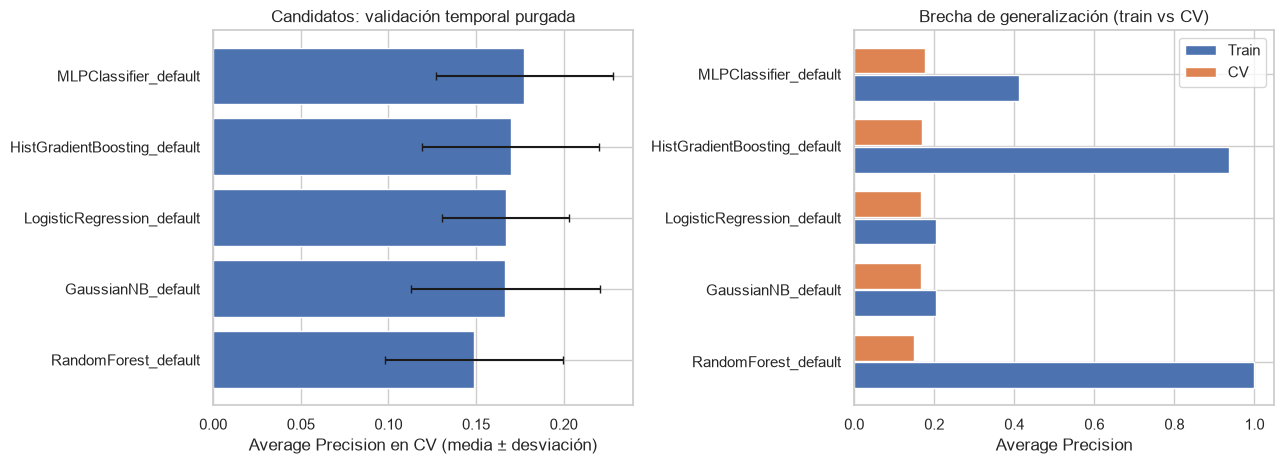

In [6]:
df_candidatos = df_comparacion[df_comparacion['fase'] == 'candidato'].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
compar = df_candidatos.sort_values('pr_auc_cv_mean')
axes[0].barh(compar['modelo'], compar['pr_auc_cv_mean'], xerr=compar['pr_auc_cv_std'], capsize=3)
axes[0].set_xlabel('Average Precision en CV (media ± desviación)')
axes[0].set_title('Candidatos: validación temporal purgada')
axes[0].set_xlim(left=0)

pos = np.arange(len(compar))
axes[1].barh(pos - 0.19, compar['pr_auc_train'], height=0.36, label='Train')
axes[1].barh(pos + 0.19, compar['pr_auc_cv_mean'], height=0.36, label='CV')
axes[1].set_yticks(pos, compar['modelo'])
axes[1].set_xlabel('Average Precision')
axes[1].set_title('Brecha de generalización (train vs CV)')
axes[1].legend()
fig.tight_layout()
plt.show()  # No se guarda ningún archivo de imagen.

## 5. Ensamblajes frente a red neuronal y coste computacional

La tabla presenta los tres enfoques que ya se evaluaron y permite discutir precisión, estabilidad y coste. El análisis de importancia por permutación se pospone a `05_seleccion`, tras elegir finalistas, para no utilizar el hold-out durante la selección.

In [7]:
familias_interes = ['Bagging','Boosting','Red_Neuronal']
display(df_candidatos[df_candidatos.familia.isin(familias_interes)][
    ['modelo','pr_auc_train','pr_auc_cv_mean','pr_auc_cv_std','brecha_train_cv','segundos_entrenamiento']
].sort_values('pr_auc_cv_mean',ascending=False))

ranking = df_candidatos.sort_values('pr_auc_cv_mean', ascending=False)
print('Tres mejores candidatos según CV temporal (para revisar en tuning):')
display(ranking.head(3)[['modelo','familia','pr_auc_cv_mean','pr_auc_cv_std']])
print('La selección definitiva se realizará tras el tuning y la evaluación final única en 05.')

,modelo,pr_auc_train,pr_auc_cv_mean,pr_auc_cv_std,brecha_train_cv,segundos_entrenamiento
6,MLPClassifier_default,0.412822,0.177512,0.050635,0.235311,0.628253
5,HistGradientBoosting_default,0.937262,0.169755,0.050386,0.767507,0.250855
4,RandomForest_default,0.998895,0.148897,0.050942,0.849998,0.183049


Tres mejores candidatos según CV temporal (para revisar en tuning):


,modelo,familia,pr_auc_cv_mean,pr_auc_cv_std
6,MLPClassifier_default,Red_Neuronal,0.177512,0.050635
5,HistGradientBoosting_default,Boosting,0.169755,0.050386
3,LogisticRegression_default,Lineal_Regularizado,0.166828,0.036239


La selección definitiva se realizará tras el tuning y la evaluación final única en 05.


## 6. Prueba opcional de un LLM local con Ollama

Esta sección **llama a un modelo real** (`qwen2.5:0.5b`) si `EJECUTAR_OLLAMA = True`. Usa 20 filas de un pliegue de validación temporal (sin utilizar el hold-out), solamente variables disponibles al cierre de la sesión y sin identificadores personales. La misma muestra se evalúa con el mejor candidato tabular, ajustado solo con las filas de entrenamiento de ese pliegue.

**Preparación externa, una sola vez:** instalar Ollama y ejecutar `ollama pull qwen2.5:0.5b`. El servidor local debe responder en `http://localhost:11434`. No se necesita una API de pago. Con `EJECUTAR_OLLAMA = False` el notebook termina sin instalar ni llamar a Ollama, si se quiere replicar el experimento de Ollama se debe colocar a la varaible como True.


**Selección de la muestra y limitaciones:** Se seleccionaron 20 observaciones del último pliegue de validación temporal, con cuatro casos de abandono y dieciséis de continuidad. Esta selección estratificada garantiza la presencia de ambas clases, pero modifica la prevalencia natural del conjunto. Por ello, las métricas calculadas sobre estos 20 casos son exploratorias y no deben extrapolarse al rendimiento general del modelo. La comparación con el candidato tabular utiliza exactamente las mismas observaciones, sin consultar el hold-out.

In [9]:
import json
import requests

EJECUTAR_OLLAMA = False  # Cambiar a True si se desea probar el LLM local (Ollama)
MODELO_OLLAMA = "qwen2.5:0.5b"

if EJECUTAR_OLLAMA:
    idx_fit, idx_val = cv_temporal[-1]
    rng = np.random.default_rng(SEMILLA)

    val_pos = idx_val[y_train.iloc[idx_val].to_numpy() == 1]
    val_neg = idx_val[y_train.iloc[idx_val].to_numpy() == 0]

    n_pos = min(4, len(val_pos))
    n_neg = min(20 - n_pos, len(val_neg))

    muestra = np.sort(np.concatenate([
        rng.choice(val_pos, size=n_pos, replace=False),
        rng.choice(val_neg, size=n_neg, replace=False),
    ]))

    X_muestra = X_train.iloc[muestra]
    y_muestra = y_train.iloc[muestra]

    # Esquema JSON que Ollama debe respetar
    esquema = {
        "type": "object",
        "properties": {
            "prob_abandono": {
                "type": "number",
                "minimum": 0,
                "maximum": 1
            }
        },
        "required": ["prob_abandono"],
        "additionalProperties": False
    }

    pred_llm = []
    latencias = []

    for i, (_, fila) in enumerate(X_muestra.iterrows(), 1):

        variables = {
            "numero_sesion": int(fila["numero_sesion"]),
            "sesiones_planificadas": int(fila["sesiones_planificadas"]),
            "progreso_plan": float(fila["progreso_plan"]),
            "dias_desde_inicio_plan": float(fila["dias_desde_inicio_plan"]),
            "cancelaciones_previas": int(fila["cancelaciones_previas"]),
            "inasistencias_previas": int(fila["inasistencias_previas"]),
            "codigo_procedimiento": str(fila["codigo_procedimiento"]),
        }

        prompt = (
            "Eres un asistente que estima exploratoriamente "
            "el riesgo de abandono de tratamientos odontológicos. "
            "Devuelve únicamente un objeto JSON con la propiedad "
            "'prob_abandono', cuyo valor sea un número entre 0 y 1. "
            "No incluyas explicaciones ni texto adicional.\n\n"
            f"Datos: {json.dumps(variables, ensure_ascii=False)}"
        )

        inicio = time.perf_counter()

        respuesta = requests.post(
            "http://localhost:11434/api/generate",
            json={
                "model": MODELO_OLLAMA,
                "prompt": prompt,
                "stream": False,
                "format": esquema,
                "options": {
                    "temperature": 0,
                    "num_predict": 256
                },
            },
            timeout=120
        )

        respuesta.raise_for_status()
        contenido = respuesta.json()

        if not contenido.get("done", False):
            raise RuntimeError(
                f"Ollama no completó la respuesta del caso {i}."
            )

        try:
            salida = json.loads(contenido["response"])
            prob = float(salida["prob_abandono"])
        except (json.JSONDecodeError, KeyError, ValueError, TypeError) as e:
            raise ValueError(
                f"Respuesta inválida en caso {i}: "
                f"{contenido.get('response')!r}"
            ) from e

        if not 0 <= prob <= 1:
            raise ValueError(
                f"Probabilidad fuera de rango en caso {i}: {prob}"
            )

        pred_llm.append(prob)
        latencias.append(time.perf_counter() - inicio)

        print(f"Caso {i:02d}/{len(muestra)}: prob={prob:.3f}")

    # Comparación sobre las mismas observaciones
    mejor_nombre = df_comparacion.loc[
        df_comparacion["fase"].eq("candidato"),
        "modelo"
    ].iloc[0]

    mejor_est = next(
        est for nombre, _, est, fase in modelos
        if nombre == mejor_nombre
    )

    mejor_fold = clone(mejor_est).fit(
        X_train.iloc[idx_fit],
        y_train.iloc[idx_fit]
    )

    pred_tabular = mejor_fold.predict_proba(X_muestra)[:, 1]

    ap_llm = average_precision_score(y_muestra, pred_llm)
    ap_tabular = average_precision_score(y_muestra, pred_tabular)

    print("\n=== COMPARACIÓN EXPLORATORIA ===")
    print(f"Ollama ({MODELO_OLLAMA}) AP: {ap_llm:.4f}")
    print(f"{mejor_nombre} AP: {ap_tabular:.4f}")
    print(f"Casos evaluados: {len(muestra)}")
    print(f"Latencia media LLM: {np.mean(latencias):.2f} s/caso")
    print("Evaluación exploratoria; no sustituye la CV temporal.")

else:
    print("Prueba con Ollama desactivada.")


Caso 01/20: prob=0.333
Caso 02/20: prob=0.250
Caso 03/20: prob=0.500
Caso 04/20: prob=0.500
Caso 05/20: prob=0.500
Caso 06/20: prob=0.500
Caso 07/20: prob=0.667
Caso 08/20: prob=0.250
Caso 09/20: prob=0.667
Caso 10/20: prob=0.750
Caso 11/20: prob=0.500
Caso 12/20: prob=0.500
Caso 13/20: prob=0.250
Caso 14/20: prob=0.250
Caso 15/20: prob=0.750
Caso 16/20: prob=0.250
Caso 17/20: prob=0.250
Caso 18/20: prob=0.333
Caso 19/20: prob=0.500
Caso 20/20: prob=0.500

=== COMPARACIÓN EXPLORATORIA ===
Ollama (qwen2.5:0.5b) AP: 0.1833
MLPClassifier_default AP: 0.2416
Casos evaluados: 20
Latencia media LLM: 2.91 s/caso
Evaluación exploratoria; no sustituye la CV temporal.


c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
